> **In this repository.** BioCLIP 2 (ViT-L/14) scored with no training: each photo is compared with text prompts for the species names (zero-shot), on `val.csv` only. It was run on Google Colab against the team's Google Drive, so its paths point to Drive; the saved outputs are the record of what it produced. To re-run it from this repository, change the data path to the folder made by `src/invasive_clf/data/download_images.py` (see `data/README.md`).

# 04 — BioCLIP 2 zero-shot on the final dataset (validation only)

Scores BioCLIP 2 (ViT-L/14) **with no training** on `downloaded_data/inat_dataset_final/val.csv`, using the **same metrics, threshold rule and plots as `modeling_experiments/experiments_TEMPLATE.ipynb`**, so the result can be put next to the fine-tuned runs (e.g. `plantnet_dinov3_vits`). `test.csv` and `test_unseen.csv` are never read.

**How zero-shot is turned into the template's format**
1. The text vocabulary is every class that appears in `train.csv` or `val.csv`: the 40 invasive classes and the background species (the held-out `test_unseen` species are *not* in it). Each class gets a text prompt; a class with several member taxa (a merged complex) gets the mean of its members' prompt embeddings.
2. Each image is compared with every class prompt; a softmax over all classes gives one probability per class.
3. The probability of invasive class *c* is that class's probability; every background class counts toward `not_invasive`. This gives the `(N, 40)` matrix the template expects.
4. The template rule then applies unchanged: predict the most likely invasive class if its probability clears a threshold `t`, otherwise `not_invasive`; `t` is tuned on val to maximise **macro-F1 over the 40 invasive classes** (primary metric). Top-1 accuracy over the 41 labels is the KPI.

Extra zero-shot metrics (not in the template): species-level top-1/top-5 over the whole vocabulary, the threshold-free *lookup* rule (predict the most likely class and look up whether it is invasive), and invasive precision re-weighted to the test set's invasive share (val is ~30 % invasive, test ~13 %).

**Runtime:** GPU (T4 is fine). About 5 min to copy images, ~2 min to download the model, a few minutes to encode. **Writes** to `modeling_runs/bioclip2_zeroshot/` in the team folder if your account can write there, otherwise to your own `ClaudeDL-invasive-plants/modeling_runs/bioclip2_zeroshot/`.

## 0. Environment

In [1]:
import importlib.util, os, subprocess, sys
_required = {"torchmetrics": "torchmetrics", "open_clip": "open_clip_torch"}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import json, math, re, shutil, time, datetime
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
import torch.nn.functional as F
import open_clip
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
import torchmetrics
from torchmetrics.classification import MulticlassF1Score, MulticlassAccuracy, MulticlassConfusionMatrix
from tqdm.auto import tqdm
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | open_clip {open_clip.__version__} | torchmetrics {torchmetrics.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

# Same plot style as experiments_TEMPLATE, so the figures look like the fine-tuning runs.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
C_BLUE, C_ORANGE, C_GRAY = "#2a78d6", "#eb6834", "#9a9995"   # template colours (gray = reference lines only)
C_AQUA = "#1baf7a"                                           # third series colour (prompt comparison)

torch 2.11.0+cu130 | open_clip 3.3.0 | torchmetrics 1.9.0 | device cuda (Tesla T4)


## 1. Settings

In [3]:
MODEL_NAME = "bioclip2_zeroshot"                 # folder name under modeling_runs/
MODEL_ID   = "hf-hub:imageomics/bioclip-2"       # BioCLIP 2 ViT-L/14 (iNat data accessed 2024-05-01; val is all post-2025-07-01)
PROMPTS    = ["scientific", "taxonomic", "taxonomic_common"]
TTA_HFLIP  = True       # average the embedding of the image and its mirror image (the template's final evaluation does this too)
EMBED_TRAIN = True      # also embed train.csv images and save them, for the next notebook (linear probe). Adds ~5 min.
TEST_INVASIVE_SHARE = 0.13   # invasive share of test.csv (1,025 / 7,931 rows, from Craig's split_per_species_counts.csv);
                             # used only to re-weight precision, test.csv itself is never read
BATCH_SIZE, NUM_WORKERS = 64, 2
LOCAL_IMG = Path("/content/images_final")        # local copy of the images: much faster than reading from Drive

TEAM_DIR = Path("/content/drive/MyDrive/fall-2026-DL-invasive-plants")
_candidates = [TEAM_DIR / "downloaded_data/inat_dataset_final",
               Path("/content/drive/Shareddrives/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final"),
               Path("../../downloaded_data/inat_dataset_final"), Path("downloaded_data/inat_dataset_final")]
DATA_ROOT = next((p for p in _candidates if (p / "val.csv").exists()), None)
assert DATA_ROOT is not None, ("dataset folder not found. If the team folder was shared with you, add it to My Drive first: "
                               "right-click it in Drive > Organize > Add shortcut.")
TEAM_RUNS = DATA_ROOT.parent.parent / "modeling_runs"

def _writable(d: Path) -> bool:
    try:
        d.mkdir(parents=True, exist_ok=True)
        probe = d / ".write_test"; probe.write_text("ok"); probe.unlink()
        return True
    except OSError:
        return False

OUT_DIR = TEAM_RUNS / MODEL_NAME
if not _writable(OUT_DIR):
    OUT_DIR = Path("/content/drive/MyDrive/ClaudeDL-invasive-plants/modeling_runs") / MODEL_NAME
    assert _writable(OUT_DIR), f"cannot write to {OUT_DIR}"
    print("team folder is read-only for this account: writing to your own folder instead")
print("DATA_ROOT:", DATA_ROOT); print("OUT_DIR  :", OUT_DIR)

DATA_ROOT: /content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final
OUT_DIR  : /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/bioclip2_zeroshot


## 2. Data (train and val only) and the class vocabulary

In [4]:
NONE_LABEL = "not_invasive"
train_df = pd.read_csv(DATA_ROOT / "train.csv")
val_df = pd.read_csv(DATA_ROOT / "val.csv")

# Same label encoding as the template: 40 invasive classes in sorted order, index 40 = not_invasive.
INVASIVE_CLASSES = sorted(c for c in train_df["label"].unique() if c != NONE_LABEL)
N_INVASIVE = len(INVASIVE_CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(INVASIVE_CLASSES)}; CLASS_TO_IDX[NONE_LABEL] = N_INVASIVE
ALL_LABELS = INVASIVE_CLASSES + [NONE_LABEL]
assert set(val_df["label"]) <= set(ALL_LABELS), "val has labels that train does not"
assert not set(train_df["observer_id"]) & set(val_df["observer_id"]), "observer leakage between train and val"
for df in (train_df, val_df):
    df["y"] = df["label"].map(CLASS_TO_IDX)
print(f"train {len(train_df)} rows | val {len(val_df)} rows ({val_df['invasive'].mean():.1%} invasive) | {N_INVASIVE} invasive classes")

# Vocabulary: one entry per class (taxon_id) seen in train or val.
rows = pd.concat([train_df, val_df], ignore_index=True)
vocab = (rows.groupby("taxon_id")
             .agg(scientific_name=("scientific_name", "first"), label=("label", "first"), group=("group", "first"),
                  common_name=("common_name", "first"), family=("family", "first"), genus=("genus", "first"),
                  n_labels=("label", "nunique"))
             .reset_index())
assert (vocab.n_labels == 1).all(), "a taxon_id carries more than one label"
# Member taxa of merged complexes (classes.csv: member_names / member_taxon_ids, ';'-separated), if available.
vocab["members"] = vocab["scientific_name"].map(lambda s: [s])
vocab["member_ids"] = vocab["taxon_id"].map(lambda t: [int(t)])
_classes_csv = DATA_ROOT / "classes.csv"
if _classes_csv.exists():
    cl = pd.read_csv(_classes_csv, usecols=lambda c: c in {"class_key", "member_names", "member_taxon_ids"}).drop_duplicates("class_key").set_index("class_key")
    for i, r in vocab.iterrows():
        if r.taxon_id in cl.index and isinstance(cl.at[r.taxon_id, "member_names"], str):
            names = [n.strip() for n in re.split(r"[;|]", cl.at[r.taxon_id, "member_names"]) if n.strip()]
            ids = [int(x) for x in re.split(r"[;|]", str(cl.at[r.taxon_id, "member_taxon_ids"])) if x.strip().isdigit()]
            if names:
                vocab.at[i, "members"] = names
            if ids:
                vocab.at[i, "member_ids"] = ids
vocab = vocab.sort_values(["label", "scientific_name"]).reset_index(drop=True)
vocab["y"] = vocab["label"].map(CLASS_TO_IDX)
VOCAB_INDEX = {t: i for i, t in enumerate(vocab.taxon_id)}
for df in (train_df, val_df):
    df["v"] = df["taxon_id"].map(VOCAB_INDEX)
M = np.zeros((len(vocab), N_INVASIVE), dtype=np.float32)            # vocab class -> invasive class (one-hot; zero row = background)
for i, yv in enumerate(vocab.y):
    if yv < N_INVASIVE:
        M[i, yv] = 1.0
print(f"vocabulary: {len(vocab)} classes ({(vocab.y < N_INVASIVE).sum()} invasive, {(vocab.y == N_INVASIVE).sum()} background); "
      f"{(vocab.members.map(len) > 1).sum()} merged complexes")
display(vocab.group.value_counts().rename("classes in vocabulary").to_frame())

train 7342 rows | val 3228 rows (30.4% invasive) | 40 invasive classes
vocabulary: 441 classes (40 invasive, 401 background); 1 merged complexes


,classes in vocabulary
group,
native_background,343
introduced_unlisted,48
invasive,40
listed_not_invasive,7
native_listed,3


## 3. Copy images to local disk

In [5]:
def copy_one(rel):
    src, dst = DATA_ROOT / rel, LOCAL_IMG / rel
    if dst.exists() and dst.stat().st_size > 0:
        return True
    dst.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(3):
        try:
            shutil.copyfile(src, dst); return True
        except OSError:
            time.sleep(2 * (attempt + 1))
    return False

def copy_split(df, name):
    t0 = time.time()
    with ThreadPoolExecutor(16) as pool:                 # 16 threads: fast, and gentler on the Drive connection than 32
        ok = list(tqdm(pool.map(copy_one, df["image_path"]), total=len(df), desc=f"copying {name}"))
    df["copied"] = ok
    print(f"{name}: copied {sum(ok)}/{len(ok)} in {time.time() - t0:.0f}s; failed: {len(ok) - sum(ok)}")

copy_split(val_df, "val")
if EMBED_TRAIN:
    copy_split(train_df, "train")
val_df = val_df[val_df["copied"]].reset_index(drop=True)

copying val:   0%|          | 0/3228 [00:00<?, ?it/s]

val: copied 3228/3228 in 172s; failed: 0


copying train:   0%|          | 0/7342 [00:00<?, ?it/s]

train: copied 7342/7342 in 189s; failed: 0


## 4. Taxonomy and prompts

In [6]:
# Kingdom..family names from the iNaturalist API (cached next to the outputs); BioCLIP was trained on taxonomic strings.
TAX_CACHE = OUT_DIR / "taxonomy_cache.json"
tax = json.load(open(TAX_CACHE)) if TAX_CACHE.exists() else {}
RANKS = ["kingdom", "phylum", "class", "order", "family"]
todo = sorted({i for ids in vocab.member_ids for i in ids} - {int(k) for k in tax})
try:
    for i in range(0, len(todo), 30):
        r = requests.get(f"https://api.inaturalist.org/v1/taxa/{','.join(map(str, todo[i:i + 30]))}", timeout=60,
                         headers={"User-Agent": "erdos-invasive-plants-bioclip/0.2"})
        r.raise_for_status()
        for t in r.json()["results"]:
            anc = {a["rank"]: a["name"] for a in t.get("ancestors", []) if a.get("rank") in RANKS}
            tax[str(t["id"])] = {"name": t["name"], "common": t.get("preferred_common_name") or "", **anc}
        time.sleep(1)
except requests.RequestException as e:
    print("iNaturalist API not reachable, falling back to the family column for missing taxa:", e)
json.dump(tax, open(TAX_CACHE, "w"))

def prompt(name, member_id, row, kind):
    if kind == "scientific":
        return f"a photo of {name}"
    t = tax.get(str(member_id), {})
    ranks = [t.get(r, "") for r in RANKS] if t else ["Plantae", "Tracheophyta", "", "", row.family]
    text = "a photo of " + " ".join(p for p in ranks + [name] if p)
    common = t.get("common") or (row.common_name if isinstance(row.common_name, str) else "")
    if kind == "taxonomic_common" and common:
        text += f" with common name {common}"
    return text

def class_prompts(row, kind):
    ids = row.member_ids if len(row.member_ids) == len(row.members) else [row.taxon_id] * len(row.members)
    return [prompt(n, i, row, kind) for n, i in zip(row.members, ids)]

missing = [r.scientific_name for r in vocab.itertuples() if not any(str(i) in tax for i in r.member_ids)]
print("taxonomy missing for:", missing or "none")
ex = vocab.iloc[0]
for k in PROMPTS:
    print(f"{k:>17}: {class_prompts(ex, k)[0]}")

taxonomy missing for: none
       scientific: a photo of Ailanthus altissima
        taxonomic: a photo of Plantae Tracheophyta Magnoliopsida Sapindales Simaroubaceae Ailanthus altissima
 taxonomic_common: a photo of Plantae Tracheophyta Magnoliopsida Sapindales Simaroubaceae Ailanthus altissima with common name tree-of-heaven


## 5. Model, text embeddings and image embeddings

In [7]:
model, _, preprocess = open_clip.create_model_and_transforms(MODEL_ID)
tokenizer = open_clip.get_tokenizer(MODEL_ID)
model = model.to(DEVICE).eval()
LOGIT_SCALE = model.logit_scale.exp().item()
amp = dict(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda")

@torch.no_grad()
def encode_texts(texts):
    out = []
    for i in range(0, len(texts), 256):
        with torch.autocast(**amp):
            e = model.encode_text(tokenizer(texts[i:i + 256]).to(DEVICE)).float()
        out.append(F.normalize(e, dim=-1).cpu())
    return torch.cat(out)

text_emb = {}
for k in PROMPTS:
    per_class = [class_prompts(r, k) for r in vocab.itertuples()]
    flat = encode_texts([p for ps in per_class for p in ps])
    sizes = [len(ps) for ps in per_class]
    text_emb[k] = F.normalize(torch.stack([chunk.mean(0) for chunk in torch.split(flat, sizes)]), dim=-1)  # mean over complex members
print({k: tuple(v.shape) for k, v in text_emb.items()})

open_clip_config.json:   0%|          | 0.00/534 [00:00<?, ?B/s]

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

{'scientific': (441, 768), 'taxonomic': (441, 768), 'taxonomic_common': (441, 768)}


In [8]:
class ImageSet(Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        try:
            return preprocess(ImageOps.exif_transpose(Image.open(LOCAL_IMG / self.paths[i])).convert("RGB")), i
        except Exception:
            return None

def _collate(batch):
    batch = [b for b in batch if b is not None]
    if not batch: return None
    x, idx = zip(*batch)
    return torch.stack(x), torch.tensor(idx)

@torch.no_grad()
def encode_images(df, name):
    dl = DataLoader(ImageSet(df["image_path"]), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, collate_fn=_collate)
    dim = text_emb[PROMPTS[0]].shape[1]
    plain, flip = torch.zeros(len(df), dim), torch.zeros(len(df), dim)
    seen = torch.zeros(len(df), dtype=torch.bool)
    for b in tqdm(dl, desc=f"encoding {name}"):
        if b is None: continue
        x, idx = b; x = x.to(DEVICE)
        with torch.autocast(**amp):
            plain[idx] = F.normalize(model.encode_image(x).float(), dim=-1).cpu()
            flip[idx] = F.normalize(model.encode_image(torch.flip(x, dims=[3])).float(), dim=-1).cpu()
        seen[idx] = True
    print(f"{name}: {int(seen.sum())}/{len(df)} images encoded; unreadable: {int((~seen).sum())}")
    return plain, flip, seen

t0 = time.time()
val_plain, val_flip, val_seen = encode_images(val_df, "val")
print(f"val encoded in {time.time() - t0:.0f}s")
val_df = val_df[val_seen.numpy()].reset_index(drop=True)
val_plain, val_flip = val_plain[val_seen], val_flip[val_seen]
val_emb = F.normalize(val_plain + val_flip, dim=-1) if TTA_HFLIP else val_plain

encoding val:   0%|          | 0/51 [00:00<?, ?it/s]

val: 3228/3228 images encoded; unreadable: 0
val encoded in 76s


## 6. Metrics

`predict_not_invasive`, `macro_f1_invasive`, `tune_threshold` and `compute_metrics` are copied **unchanged** from `experiments_TEMPLATE.ipynb` (Section 5), so every number means the same as in the fine-tuning runs. The zero-shot extras come after them.

In [9]:
# ---------- copied unchanged from experiments_TEMPLATE.ipynb, Section 5 ----------
def predict_not_invasive(probs: np.ndarray, t: float) -> np.ndarray:
    # Species when the strongest invasive probability clears t, otherwise not_invasive.
    pred = probs.argmax(1)
    pred[probs.max(1) < t] = N_INVASIVE
    return pred


def macro_f1_invasive(y: np.ndarray, pred: np.ndarray) -> float:
    f1 = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y))
    return float(f1[:N_INVASIVE].mean())


def tune_threshold(probs, y, grid):
    # Sweep the grid; return the best t plus the full sweep for plotting.
    sweep = pd.DataFrame({"threshold": grid})
    sweep["macro_f1_invasive"] = [macro_f1_invasive(y, predict_not_invasive(probs, t)) for t in grid]
    sweep["top1_acc_all"] = [float((predict_not_invasive(probs, t) == y).mean()) for t in grid]
    best = sweep.loc[sweep["macro_f1_invasive"].idxmax()]
    return float(best["threshold"]), sweep


def compute_metrics(probs: np.ndarray, y: np.ndarray, threshold: float | None, grid) -> dict:
    probs = np.asarray(probs, dtype=np.float64); y = np.asarray(y)
    is_inv = y < N_INVASIVE
    onehot = np.eye(N_INVASIVE + 1)[y][:, :N_INVASIVE]              # (N, N_INVASIVE) binary targets

    m = {}
    # threshold-free, ranking metrics over the invasive classes
    per_class_ap = np.array([average_precision_score(onehot[:, c], probs[:, c]) if onehot[:, c].any() else np.nan
                             for c in range(N_INVASIVE)])
    m["macro_ap_invasive"] = float(np.nanmean(per_class_ap))
    if is_inv.any():
        rank = (-probs[is_inv]).argsort(1)
        m["top1_recall_invasive"] = float((rank[:, 0] == y[is_inv]).mean())
        m["top3_recall_invasive"] = float((rank[:, :3] == y[is_inv, None]).any(1).mean())
    # threshold
    sweep = None
    if threshold is None:
        threshold, sweep = tune_threshold(probs, y, grid)
    m["threshold"] = float(threshold)
    pred = predict_not_invasive(probs, threshold)
    # 41-way metrics at the fixed threshold
    f1_per_class = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y)).numpy()
    m["macro_f1_invasive"] = float(f1_per_class[:N_INVASIVE].mean())
    m["macro_f1_all41"] = float(f1_per_class.mean())
    m["top1_acc_all"] = float(MulticlassAccuracy(num_classes=N_INVASIVE + 1, average="micro")(torch.as_tensor(pred), torch.as_tensor(y)))
    # binary invasive detection
    score_inv = probs.max(1); pred_inv = pred < N_INVASIVE
    m["bin_precision_invasive"] = precision_score(is_inv, pred_inv, zero_division=0)
    m["bin_recall_invasive"] = recall_score(is_inv, pred_inv, zero_division=0)
    m["bin_f1_invasive"] = f1_score(is_inv, pred_inv, zero_division=0)
    m["bin_ap_invasive"] = average_precision_score(is_inv, score_inv)
    m["bin_auroc_invasive"] = roc_auc_score(is_inv, score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # the not_invasive side
    m["noninv_precision"] = precision_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_recall"] = recall_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_auroc"] = roc_auc_score(~is_inv, 1 - score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # arrays
    m["per_class_f1"] = f1_per_class.tolist()
    m["per_class_ap"] = per_class_ap.tolist()
    m["confusion_matrix"] = MulticlassConfusionMatrix(num_classes=N_INVASIVE + 1)(torch.as_tensor(pred), torch.as_tensor(y)).numpy().tolist()
    m["_sweep"] = sweep; m["_pred"] = pred
    return m

SCALAR_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
                  "threshold", "bin_precision_invasive", "bin_recall_invasive", "bin_f1_invasive", "bin_ap_invasive",
                  "bin_auroc_invasive", "noninv_precision", "noninv_recall", "noninv_auroc", "macro_f1_all41"]
KEY_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
               "bin_precision_invasive", "bin_recall_invasive", "bin_auroc_invasive", "noninv_auroc", "threshold"]

def scalars(m: dict) -> dict:
    return {k: m[k] for k in SCALAR_METRICS if k in m}

THRESHOLD_GRID = [round(t, 3) for t in np.linspace(0.01, 0.99, 99)]    # the template's threshold_grid

In [10]:
# ---------- zero-shot specific ----------
def zero_shot_probs(img_emb, txt_emb):
    # softmax over every vocabulary class -> (N, V); invasive-class probabilities -> (N, 40) in the template's format
    p_vocab = torch.softmax(LOGIT_SCALE * img_emb @ txt_emb.T, dim=1).numpy()
    return p_vocab, p_vocab @ M

def reweighted_precision(is_inv, pred_inv, target_share):
    # Precision if invasives made up `target_share` of the images instead of their val share (prior-shift correction).
    share = is_inv.mean()
    tp = (is_inv & pred_inv).sum() * target_share / share
    fp = (~is_inv & pred_inv).sum() * (1 - target_share) / (1 - share)
    return float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0

def zero_shot_extras(p_vocab, m, df):
    y, v = df["y"].to_numpy(), df["v"].to_numpy()
    is_inv = y < N_INVASIVE
    top5 = np.argsort(-p_vocab, axis=1)[:, :5]
    lookup = vocab.y.to_numpy()[top5[:, 0]]                  # predict the most likely class, look up its label
    f1_lookup = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(lookup), torch.as_tensor(y)).numpy()
    return {"species_top1": float((top5[:, 0] == v).mean()),
            "species_top5": float((top5 == v[:, None]).any(1).mean()),
            "lookup_macro_f1_invasive": float(f1_lookup[:N_INVASIVE].mean()),
            "lookup_top1_acc_all": float((lookup == y).mean()),
            "lookup_bin_recall_invasive": float((lookup[is_inv] < N_INVASIVE).mean()),
            "lookup_false_alarm_rate": float((lookup[~is_inv] < N_INVASIVE).mean()),
            "false_alarm_rate": float((m["_pred"][~is_inv] < N_INVASIVE).mean()),
            "bin_precision_invasive_testmix": reweighted_precision(is_inv, m["_pred"] < N_INVASIVE, TEST_INVASIVE_SHARE)}

## 7. Evaluate the three prompts (chosen on val, as the template chooses hyperparameters)

In [11]:
y_val = val_df["y"].to_numpy()
results, runs = [], {}
for k in PROMPTS:
    p_vocab, p_inv = zero_shot_probs(val_emb, text_emb[k])
    m = compute_metrics(p_inv, y_val, None, THRESHOLD_GRID)
    extras = zero_shot_extras(p_vocab, m, val_df)
    runs[k] = {"p_vocab": p_vocab, "p_inv": p_inv, "m": m, "extras": extras}
    results.append({"prompt": k, **scalars(m), **extras})
summary = pd.DataFrame(results).set_index("prompt")
BEST = summary["macro_f1_invasive"].idxmax()
display(summary[KEY_METRICS + ["species_top1", "species_top5", "lookup_macro_f1_invasive", "false_alarm_rate",
                               "bin_precision_invasive_testmix"]].T.round(4))
print("best prompt on val (macro-F1, invasive):", BEST)
# Without TTA, for reference
p_plain = zero_shot_probs(val_plain, text_emb[BEST])[1]
m_plain = compute_metrics(p_plain, y_val, None, THRESHOLD_GRID)
print(f"{BEST} without TTA: macro-F1 {m_plain['macro_f1_invasive']:.4f}, top-1 {m_plain['top1_acc_all']:.4f}")

prompt,scientific,taxonomic,taxonomic_common
macro_f1_invasive,0.9674,0.9678,0.9655
top1_acc_all,0.9820,0.9830,0.9817
macro_ap_invasive,0.9909,0.9915,0.9907
top1_recall_invasive,0.9756,0.9735,0.9756
top3_recall_invasive,0.9929,0.9939,0.9939
bin_precision_invasive,0.9957,0.9916,0.9885
bin_recall_invasive,0.9542,0.9633,0.9633
bin_auroc_invasive,0.9985,0.9985,0.9984
noninv_auroc,0.9985,0.9985,0.9984
threshold,0.4100,0.3300,0.3000


best prompt on val (macro-F1, invasive): taxonomic
taxonomic without TTA: macro-F1 0.9648, top-1 0.9823


## 8. Save (same files as a template run, one folder per prompt)

In [12]:
for k, r in runs.items():
    d = OUT_DIR / k; d.mkdir(parents=True, exist_ok=True)
    m, ex = r["m"], r["extras"]
    out = {"model": MODEL_NAME, "iteration": k, "best_epoch": None, "epochs": 0, "tta_hflip": TTA_HFLIP, "train_minutes": 0.0,
           **scalars(m), **ex, "per_class_f1": dict(zip(ALL_LABELS, m["per_class_f1"])),
           "per_class_ap": dict(zip(INVASIVE_CLASSES, m["per_class_ap"])), "labels": ALL_LABELS,
           "confusion_matrix": m["confusion_matrix"]}
    json.dump(out, open(d / "metrics_final.json", "w"), indent=1, default=float)
    json.dump({"model_id": MODEL_ID, "prompt": k, "tta_hflip": TTA_HFLIP, "vocabulary": "train+val classes",
               "n_vocab": len(vocab), "threshold_grid": THRESHOLD_GRID}, open(d / "config.json", "w"), indent=1)
    top = np.argsort(-r["p_vocab"], axis=1)[:, :3]
    pd.DataFrame({"observation_id": val_df["observation_id"], "label": val_df["label"], "group": val_df["group"],
                  "scientific_name": val_df["scientific_name"], "pred": [ALL_LABELS[i] for i in m["_pred"]],
                  "max_prob": r["p_inv"].max(1), "argmax_class": [INVASIVE_CLASSES[i] for i in r["p_inv"].argmax(1)],
                  "top1_species": vocab.scientific_name.values[top[:, 0]], "top1_prob": r["p_vocab"][np.arange(len(top)), top[:, 0]].round(4),
                  "top2_species": vocab.scientific_name.values[top[:, 1]], "top3_species": vocab.scientific_name.values[top[:, 2]]}
                 ).to_csv(d / "val_predictions.csv", index=False)
    np.save(d / "val_probs_invasive.npy", r["p_inv"].astype(np.float32))   # full (N, 40) matrix, for ensembling later

# Prompt choice recorded like the template's decision log
json.dump([{"name": k, "decision": "accepted" if k == BEST else "rejected", "overrides": {"prompt": k}, "note": "prompt chosen on val",
            "macro_f1_invasive": float(summary.at[k, "macro_f1_invasive"]), "top1_acc_all": float(summary.at[k, "top1_acc_all"]),
            "when": datetime.datetime.now().isoformat(timespec="seconds")} for k in PROMPTS],
          open(OUT_DIR / "decisions.json", "w"), indent=1)
summary.to_csv(OUT_DIR / "summary_prompts.csv")
np.savez_compressed(OUT_DIR / "embeddings_val.npz", observation_id=val_df["observation_id"].to_numpy(),
                    image_emb=val_plain.numpy().astype(np.float16), image_emb_flip=val_flip.numpy().astype(np.float16),
                    vocab_taxon_id=vocab.taxon_id.to_numpy(), vocab_label=vocab.label.to_numpy(),
                    **{f"text_{k}": text_emb[k].numpy().astype(np.float16) for k in PROMPTS})
print("saved to", OUT_DIR)

saved to /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/bioclip2_zeroshot


In [13]:
# Train embeddings for the next notebook (linear probe / text-initialised head). Train images are NOT used for any metric here.
if EMBED_TRAIN:
    tr = train_df[train_df["copied"]].reset_index(drop=True)
    tr_plain, tr_flip, tr_seen = encode_images(tr, "train")
    np.savez_compressed(OUT_DIR / "embeddings_train.npz", observation_id=tr["observation_id"].to_numpy()[tr_seen.numpy()],
                        image_emb=tr_plain[tr_seen].numpy().astype(np.float16), image_emb_flip=tr_flip[tr_seen].numpy().astype(np.float16))
    print("saved embeddings_train.npz")

encoding train:   0%|          | 0/115 [00:00<?, ?it/s]

train: 7342/7342 images encoded; unreadable: 0
saved embeddings_train.npz


## 9. Plots

The first four are the template's own plot functions (copied unchanged, minus the training-curve plot, which needs epochs), applied to the best prompt. The rest are zero-shot specific. Every figure is saved as PNG in `OUT_DIR/<prompt>/` or `OUT_DIR/`.

In [14]:
# ---------- copied unchanged from experiments_TEMPLATE.ipynb, Section 5b ----------
def plot_threshold_sweep(sweep: pd.DataFrame, t: float, out_dir: Path, title=""):
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(sweep["threshold"], sweep["macro_f1_invasive"], color=C_BLUE, lw=2, label="macro-F1 (invasive)")
    ax.plot(sweep["threshold"], sweep["top1_acc_all"], color=C_ORANGE, lw=2, label="top-1 accuracy (41)")
    ax.axvline(t, color=C_GRAY, ls="--", lw=1); ax.text(t, 0.02, f" t = {t:.2f}", fontsize=8)
    ax.set_xlabel("invasive threshold on max class probability"); ax.set_ylim(0, 1); ax.legend(fontsize=8)
    ax.set_title(title or "threshold sweep (validation)", fontsize=8); fig.tight_layout(); fig.savefig(out_dir / "threshold_sweep.png"); plt.show()


def plot_pr_roc(probs, y, m: dict, out_dir: Path, title=""):
    is_inv = y < N_INVASIVE; score = probs.max(1); t = m["threshold"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    # binary PR curve: invasive vs not
    p, r, th = precision_recall_curve(is_inv, score)
    ax = axes[0]; ax.plot(r, p, color=C_BLUE, lw=2)
    ax.scatter([m["bin_recall_invasive"]], [m["bin_precision_invasive"]], color=C_ORANGE, s=40, zorder=3, label=f"operating point, t={t:.2f}")
    ax.axhline(is_inv.mean(), color=C_GRAY, ls=":", lw=1, label=f"prevalence {is_inv.mean():.2f}")
    ax.set_xlabel("recall (invasive)"); ax.set_ylabel("precision (invasive)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"binary invasive detection: AP = {m['bin_ap_invasive']:.3f}"); ax.legend(fontsize=7, loc="lower left")
    # per-class PR curves
    ax = axes[1]
    for c in range(N_INVASIVE):
        yc = (y == c)
        if yc.any():
            pc, rc, _ = precision_recall_curve(yc, probs[:, c]); ax.plot(rc, pc, color=C_BLUE, alpha=0.25, lw=1)
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"per-class PR, {N_INVASIVE} invasive classes: macro-AP = {m['macro_ap_invasive']:.3f}")
    # ROC
    ax = axes[2]
    if 0 < is_inv.sum() < len(y):
        fpr, tpr, _ = roc_curve(is_inv, score); ax.plot(fpr, tpr, color=C_BLUE, lw=2)
        fpr_t = float((~is_inv & (score >= t)).sum() / max((~is_inv).sum(), 1))
        ax.scatter([fpr_t], [m["bin_recall_invasive"]], color=C_ORANGE, s=40, zorder=3)
    ax.plot([0, 1], [0, 1], color=C_GRAY, ls=":", lw=1)
    ax.set_xlabel("false-positive rate (not_invasive flagged)"); ax.set_ylabel("true-positive rate (invasive found)")
    ax.set_title(f"ROC: AUROC = {m['bin_auroc_invasive']:.3f}")
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "pr_roc.png"); plt.show()


def plot_confusion(m: dict, out_dir: Path, title="", normalize=True):
    cm = np.array(m["confusion_matrix"], dtype=float)
    if normalize:
        cm = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(len(ALL_LABELS))); ax.set_yticks(range(len(ALL_LABELS)))
    ax.set_xticklabels(ALL_LABELS, rotation=90, fontsize=6); ax.set_yticklabels(ALL_LABELS, fontsize=6)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(title or ("confusion matrix, row-normalised (recall on the diagonal)" if normalize else "confusion matrix (counts)"))
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); fig.tight_layout(); fig.savefig(out_dir / "confusion_matrix.png"); plt.show()


def plot_per_class_f1(m: dict, out_dir: Path, support: pd.Series, title=""):
    f1 = pd.Series(m["per_class_f1"][:N_INVASIVE], index=INVASIVE_CLASSES).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.22 * N_INVASIVE + 1.5))
    ax.barh(f1.index, f1.values, color=C_BLUE, height=0.7)
    for i, (name, v) in enumerate(f1.items()):
        ax.text(min(v + 0.01, 0.9), i, f"n={int(support.get(name, 0))}", va="center", fontsize=6, color="#52514e")
    ax.set_xlim(0, 1); ax.set_xlabel("F1 on validation (at the tuned threshold)"); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(title or f"per-class F1; macro-F1 (invasive) = {m['macro_f1_invasive']:.3f}")
    fig.tight_layout(); fig.savefig(out_dir / "per_class_f1.png"); plt.show()

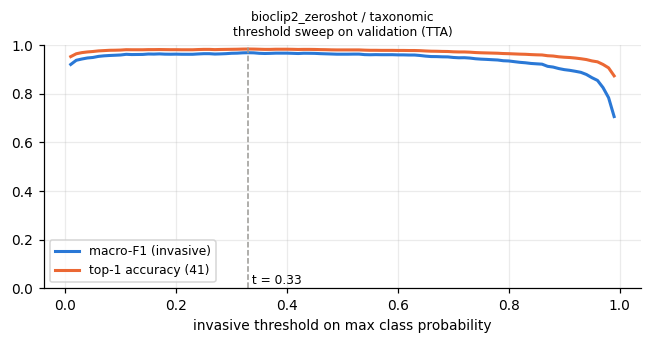

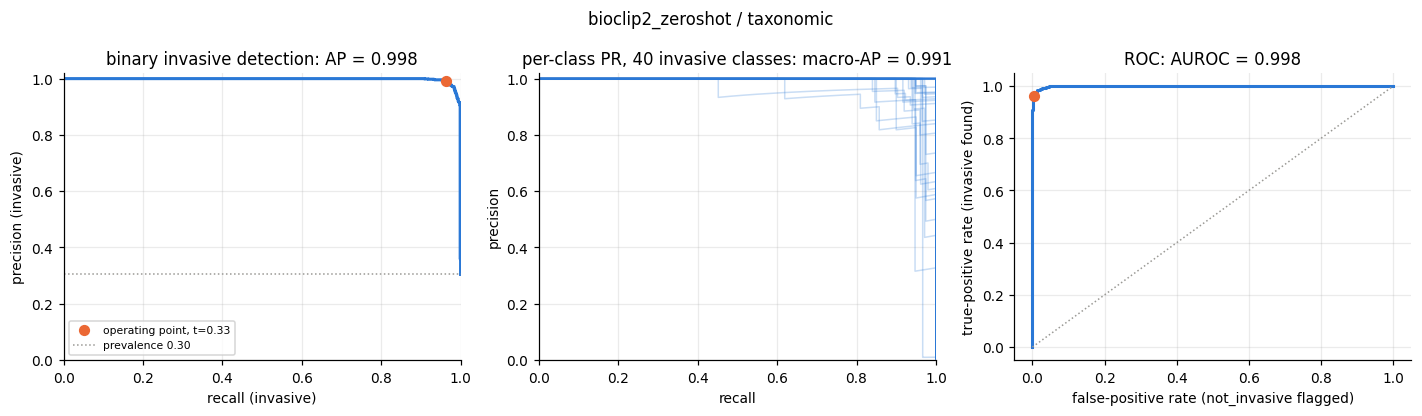

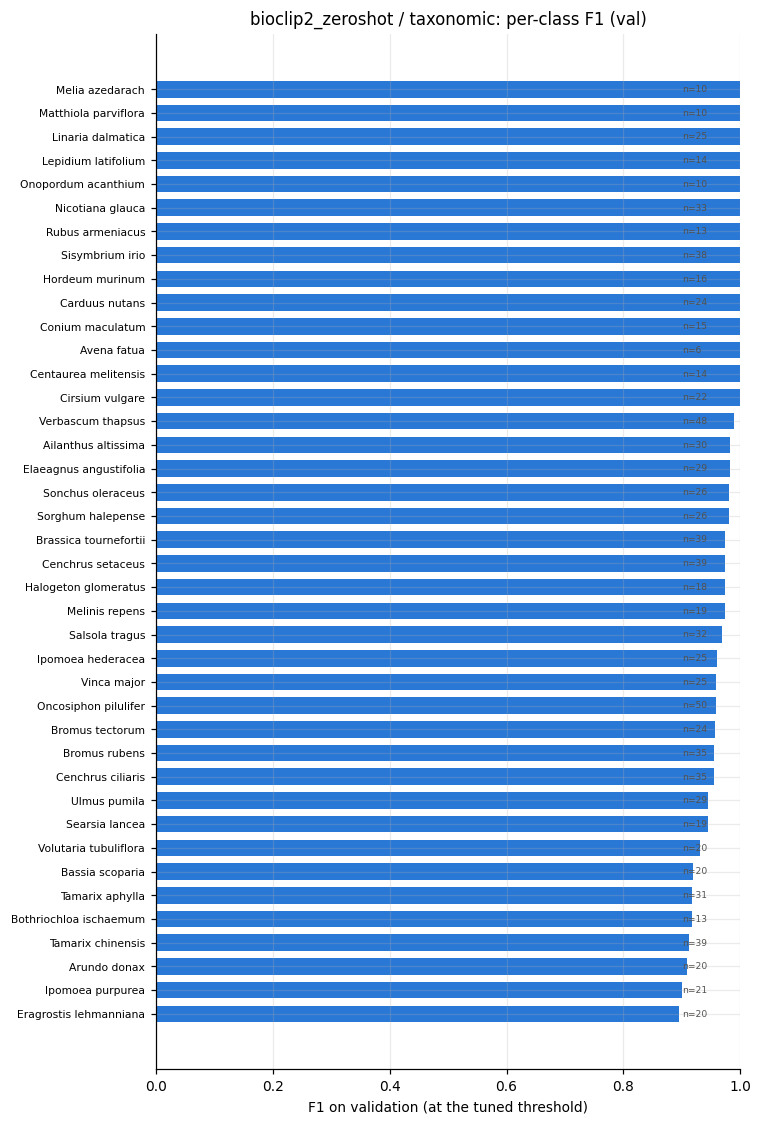

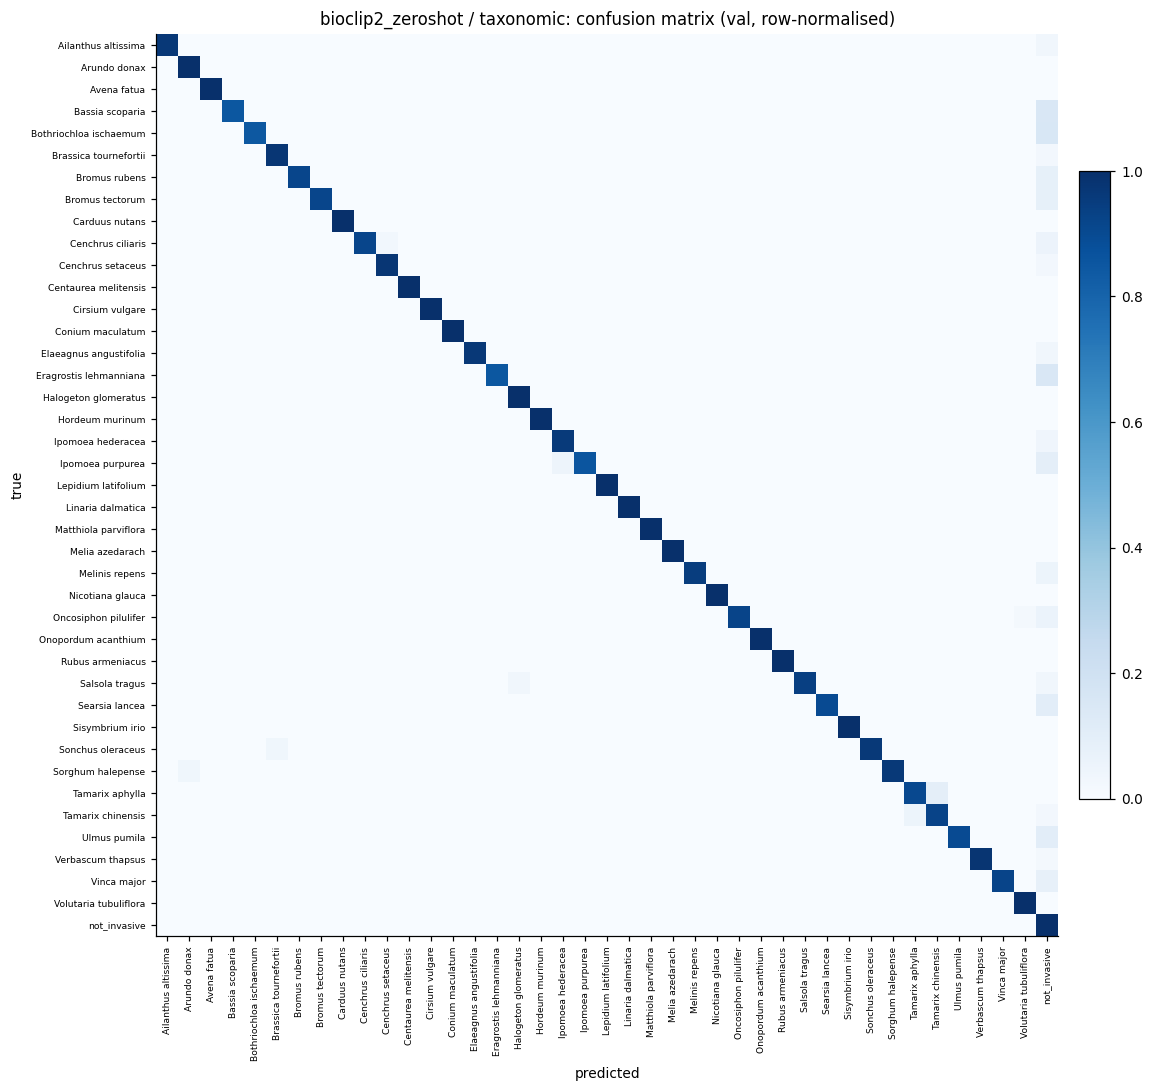

In [15]:
best_dir, rb = OUT_DIR / BEST, runs[BEST]
ttl = f"{MODEL_NAME} / {BEST}"
plot_threshold_sweep(rb["m"]["_sweep"], rb["m"]["threshold"], best_dir, f"{ttl}\nthreshold sweep on validation (TTA)")
plot_pr_roc(rb["p_inv"], y_val, rb["m"], best_dir, ttl)
plot_per_class_f1(rb["m"], best_dir, val_df["label"].value_counts(), f"{ttl}: per-class F1 (val)")
plot_confusion(rb["m"], best_dir, f"{ttl}: confusion matrix (val, row-normalised)")

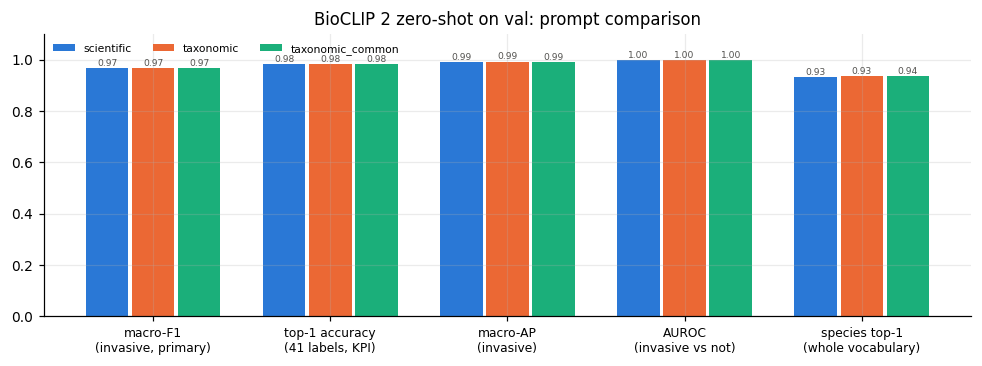

In [16]:
# (a) The three prompts side by side
show = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "bin_auroc_invasive", "species_top1"]
nice = {"macro_f1_invasive": "macro-F1\n(invasive, primary)", "top1_acc_all": "top-1 accuracy\n(41 labels, KPI)",
        "macro_ap_invasive": "macro-AP\n(invasive)", "bin_auroc_invasive": "AUROC\n(invasive vs not)", "species_top1": "species top-1\n(whole vocabulary)"}
colors = dict(zip(PROMPTS, [C_BLUE, C_ORANGE, C_AQUA]))
fig, ax = plt.subplots(figsize=(9, 3.4)); w = 0.26; x = np.arange(len(show))
for j, k in enumerate(PROMPTS):
    vals = summary.loc[k, show].to_numpy(dtype=float)
    bars = ax.bar(x + (j - 1) * w, vals, width=w - 0.02, color=colors[k], label=k)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=6, color="#52514e")
ax.set_xticks(x); ax.set_xticklabels([nice[s] for s in show], fontsize=8); ax.set_ylim(0, 1.1)
ax.set_title("BioCLIP 2 zero-shot on val: prompt comparison"); ax.legend(fontsize=7, ncol=3, frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(OUT_DIR / "prompt_comparison.png"); plt.show()

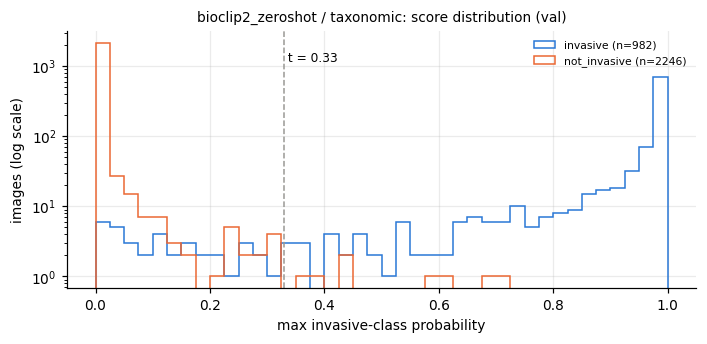

In [17]:
# (b) How separable are invasives? Distribution of the score the threshold is applied to
score = rb["p_inv"].max(1); is_inv = y_val < N_INVASIVE; t = rb["m"]["threshold"]
fig, ax = plt.subplots(figsize=(6.5, 3.2)); bins = np.linspace(0, 1, 41)
ax.hist(score[is_inv], bins=bins, histtype="step", lw=2, color=C_BLUE, label=f"invasive (n={is_inv.sum()})")
ax.hist(score[~is_inv], bins=bins, histtype="step", lw=2, color=C_ORANGE, label=f"not_invasive (n={(~is_inv).sum()})")
ax.axvline(t, color=C_GRAY, ls="--", lw=1); ax.text(t, ax.get_ylim()[1] * 0.5, f" t = {t:.2f}", fontsize=8)
ax.set_yscale("log"); ax.set_xlabel("max invasive-class probability"); ax.set_ylabel("images (log scale)")
ax.set_title(f"{ttl}: score distribution (val)", fontsize=9); ax.legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(best_dir / "score_distribution.png"); plt.show()

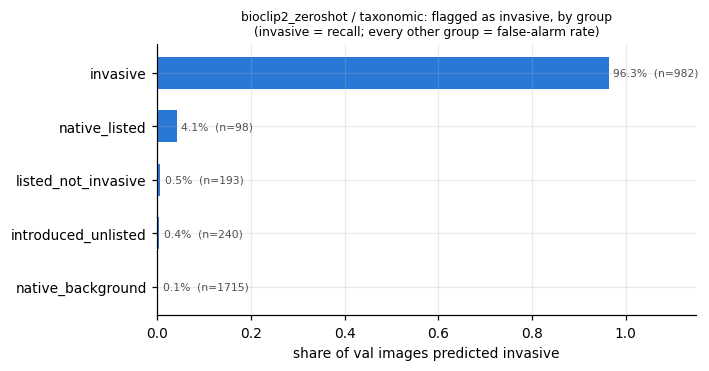

In [18]:
# (c) Who gets flagged? Share of each group predicted invasive (recall for 'invasive', false-alarm rate for the others)
pred_inv = rb["m"]["_pred"] < N_INVASIVE
g = (val_df.assign(flagged=pred_inv).groupby("group")["flagged"].agg(["mean", "size"]).sort_values("mean"))
fig, ax = plt.subplots(figsize=(6.5, 0.45 * len(g) + 1.2))
ax.barh(g.index, g["mean"], color=C_BLUE, height=0.6)
for i, (name, r) in enumerate(g.iterrows()):
    ax.text(r["mean"] + 0.01, i, f"{r['mean']:.1%}  (n={int(r['size'])})", va="center", fontsize=7, color="#52514e")
ax.set_xlim(0, 1.15); ax.set_xlabel("share of val images predicted invasive")
ax.set_title(f"{ttl}: flagged as invasive, by group\n(invasive = recall; every other group = false-alarm rate)", fontsize=8)
fig.tight_layout(); fig.savefig(best_dir / "flagged_by_group.png"); plt.show()

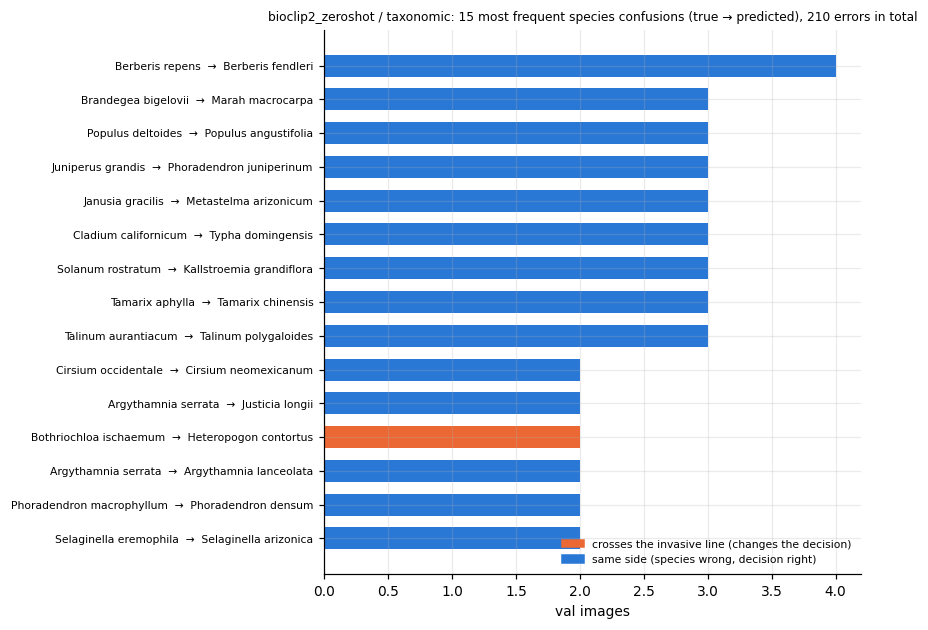

In [19]:
# (d) Most frequent species-level mistakes, marked by whether they cross the invasive / not-invasive line
top1 = rb["p_vocab"].argmax(1); v = val_df["v"].to_numpy(); wrong = top1 != v
conf = (pd.DataFrame({"true": vocab.scientific_name.values[v[wrong]], "pred": vocab.scientific_name.values[top1[wrong]],
                      "crosses": (vocab.y.values[v[wrong]] < N_INVASIVE) != (vocab.y.values[top1[wrong]] < N_INVASIVE)})
          .value_counts().reset_index(name="n").head(15).iloc[::-1])
fig, ax = plt.subplots(figsize=(8, 0.3 * len(conf) + 1.3))
ax.barh([f"{a}  →  {b}" for a, b in zip(conf.true, conf.pred)], conf.n, height=0.65,
        color=[C_ORANGE if c else C_BLUE for c in conf.crosses])
ax.tick_params(axis="y", labelsize=7); ax.set_xlabel("val images")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C_ORANGE, label="crosses the invasive line (changes the decision)"),
                   Patch(color=C_BLUE, label="same side (species wrong, decision right)")], fontsize=7, frameon=False, loc="lower right")
ax.set_title(f"{ttl}: 15 most frequent species confusions (true → predicted), {wrong.sum()} errors in total", fontsize=8)
fig.tight_layout(); fig.savefig(best_dir / "top_confusions.png"); plt.show()

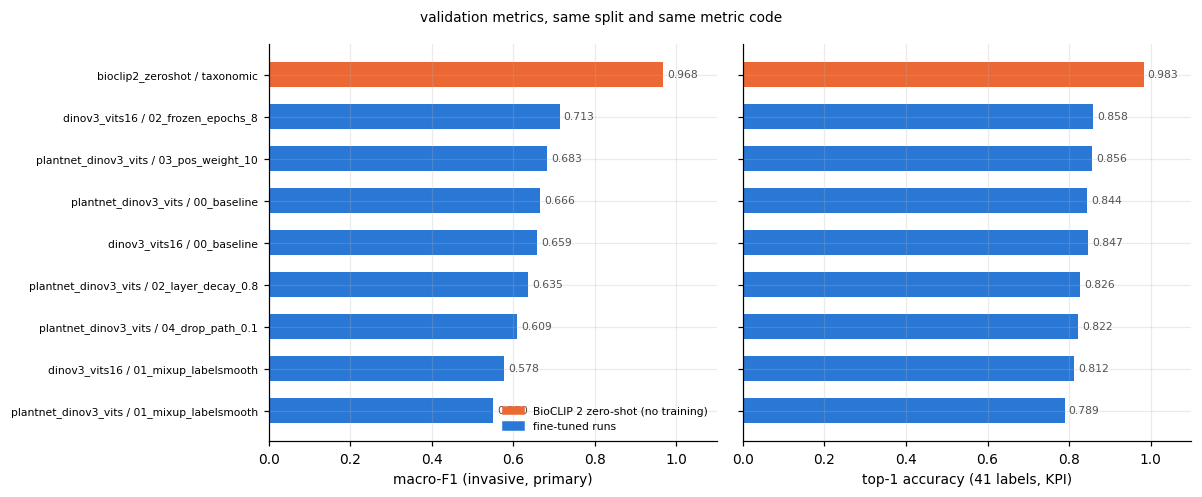

,zero_shot,macro_f1_invasive,top1_acc_all
run,,,
plantnet_dinov3_vits / 01_mixup_labelsmooth,False,0.5498,0.7890
dinov3_vits16 / 01_mixup_labelsmooth,False,0.5778,0.8123
plantnet_dinov3_vits / 04_drop_path_0.1,False,0.6093,0.8222
plantnet_dinov3_vits / 02_layer_decay_0.8,False,0.6353,0.8262
dinov3_vits16 / 00_baseline,False,0.6592,0.8467
plantnet_dinov3_vits / 00_baseline,False,0.6657,0.8442
plantnet_dinov3_vits / 03_pos_weight_10,False,0.6829,0.8556
dinov3_vits16 / 02_frozen_epochs_8,False,0.7134,0.8584
bioclip2_zeroshot / taxonomic,True,0.9678,0.9830


In [20]:
# (e) Next to the fine-tuned runs: every metrics_final.json under the team's modeling_runs (read-only)
rows_cmp = []
for f in sorted(TEAM_RUNS.glob("*/*/metrics_final.json")):
    mm = json.load(open(f))
    if f.parent.parent.name == MODEL_NAME and f.parent.name != BEST:
        continue
    rows_cmp.append({"run": f"{f.parent.parent.name} / {f.parent.name}", "zero_shot": f.parent.parent.name == MODEL_NAME,
                     "macro_f1_invasive": mm["macro_f1_invasive"], "top1_acc_all": mm["top1_acc_all"]})
if not any(r["zero_shot"] for r in rows_cmp):                      # this run was written to the personal folder
    rows_cmp.append({"run": f"{MODEL_NAME} / {BEST}", "zero_shot": True, "macro_f1_invasive": summary.at[BEST, "macro_f1_invasive"],
                     "top1_acc_all": summary.at[BEST, "top1_acc_all"]})
cmp_df = pd.DataFrame(rows_cmp).sort_values("macro_f1_invasive")
fig, axes = plt.subplots(1, 2, figsize=(11, 0.35 * len(cmp_df) + 1.4), sharey=True)
for ax, col, lab in zip(axes, ["macro_f1_invasive", "top1_acc_all"], ["macro-F1 (invasive, primary)", "top-1 accuracy (41 labels, KPI)"]):
    ax.barh(cmp_df.run, cmp_df[col], height=0.6, color=[C_ORANGE if z else C_BLUE for z in cmp_df.zero_shot])
    for i, val in enumerate(cmp_df[col]):
        ax.text(val + 0.01, i, f"{val:.3f}", va="center", fontsize=7, color="#52514e")
    ax.set_xlim(0, 1.1); ax.set_xlabel(lab); ax.tick_params(axis="y", labelsize=7)
axes[0].legend(handles=[Patch(color=C_ORANGE, label="BioCLIP 2 zero-shot (no training)"), Patch(color=C_BLUE, label="fine-tuned runs")],
               fontsize=7, frameon=False, loc="lower right")
fig.suptitle("validation metrics, same split and same metric code", fontsize=9); fig.tight_layout()
fig.savefig(OUT_DIR / "comparison_with_finetuned_runs.png"); plt.show()
display(cmp_df.set_index("run").round(4))

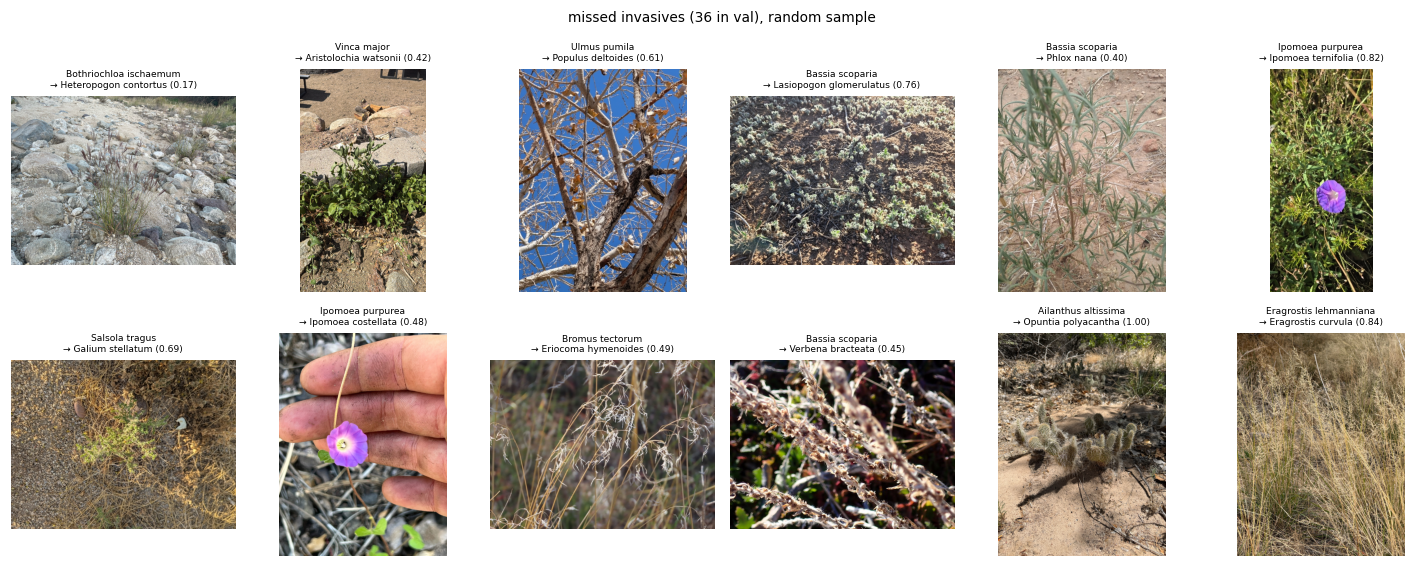

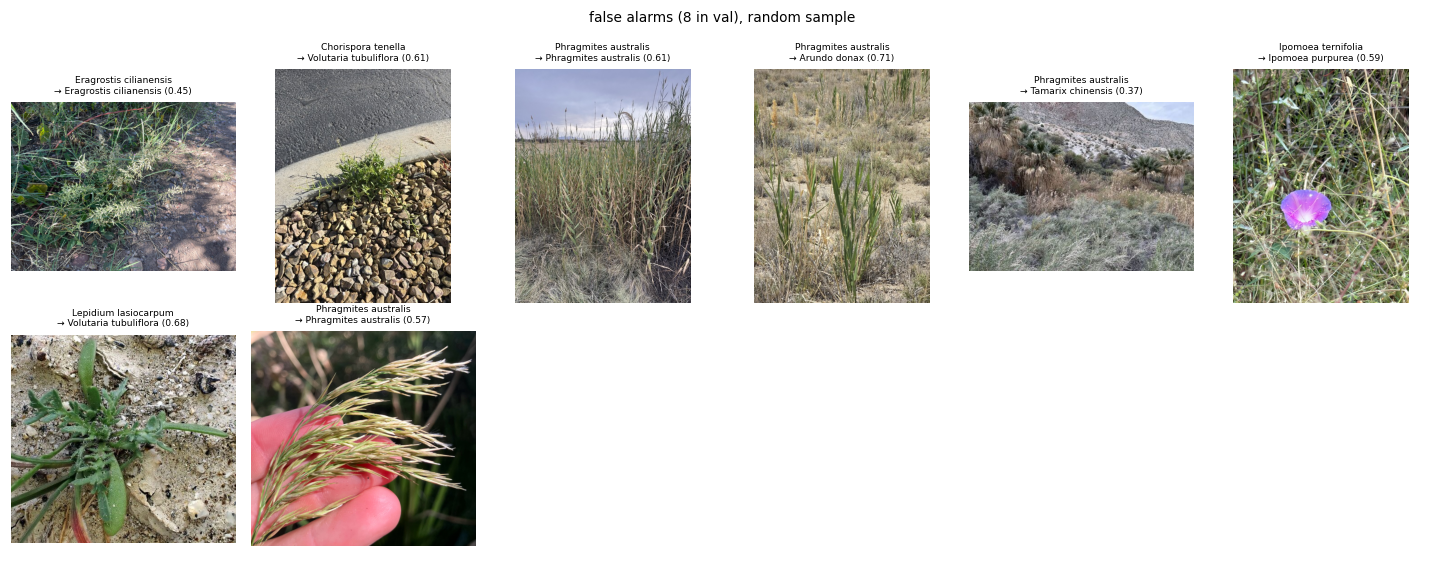

In [21]:
# (f) A look at the errors: missed invasives and false alarms (title: true / predicted species)
def gallery(idx, title, fname, n=12):
    idx = list(idx)[:n]
    if not idx:
        print(f"{title}: none"); return
    cols = 6; rows_ = math.ceil(len(idx) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * 2.2, rows_ * 2.6))
    for ax in np.ravel(axes): ax.axis("off")
    for ax, i in zip(np.ravel(axes), idx):
        ax.imshow(ImageOps.exif_transpose(Image.open(LOCAL_IMG / val_df.image_path[i])).convert("RGB"))
        ax.set_title(f"{val_df.scientific_name[i]}\n→ {vocab.scientific_name[top1[i]]} ({rb['p_vocab'][i, top1[i]]:.2f})", fontsize=6)
    fig.suptitle(title, fontsize=9); fig.tight_layout(); fig.savefig(best_dir / fname); plt.show()

rng = np.random.default_rng(0)
missed = np.flatnonzero(is_inv & ~pred_inv); false_alarm = np.flatnonzero(~is_inv & pred_inv)
gallery(rng.permutation(missed), f"missed invasives ({len(missed)} in val), random sample", "missed_invasives.png")
gallery(rng.permutation(false_alarm), f"false alarms ({len(false_alarm)} in val), random sample", "false_alarms.png")

## Notes
- **Vocabulary choice matters.** Zero-shot can only name classes it is given. Here it gets every class in train and val, which is a closed set; the `test_unseen` species are deliberately left out, so a later evaluation on `test_unseen` shows how often unknown species are mistaken for invasives.
- **Threshold.** As in the template, `t` is tuned on val for macro-F1. Val is ~30 % invasive while test is ~13 %, so `bin_precision_invasive` on val is optimistic; `bin_precision_invasive_testmix` re-weights it to the test mix.
- **Lookup rule** (`lookup_*`): no threshold, just "is the most likely species invasive?". It is the natural zero-shot decision and needs no tuning.
- **Compare on val only**; `test.csv` stays untouched until the final model.
- Saved for later: `val_probs_invasive.npy` per prompt (ensembling), `embeddings_val.npz` and `embeddings_train.npz` (linear probe / text-initialised head).